In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv")
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv")

print("Training:", train_df.shape)
print("Testing:", test_df.shape)

Training: (175341, 45)
Testing: (82332, 45)


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Binary classification target
X_train = train_df.drop(columns=["label", "attack_cat", "id"])
y_train = train_df["label"]

X_test = test_df.drop(columns=["label", "attack_cat", "id"])
y_test = test_df["label"]

# Identify categorical and numerical columns
cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()

print("Categorical features:", cat_cols)
print("Numerical features:", len(num_cols))

Categorical features: ['proto', 'service', 'state']
Numerical features: 39


In [7]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    accuracy_score
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, num_cols),
    ("categorical", categorical_pipeline, cat_cols)
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
print("Baseline model training completed.")

Baseline model training completed.


In [9]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    digits=4
))

Accuracy: 0.8705
ROC-AUC: 0.9791

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9772    0.7288    0.8349     37000
      Attack     0.8167    0.9861    0.8934     45332

    accuracy                         0.8705     82332
   macro avg     0.8969    0.8575    0.8642     82332
weighted avg     0.8888    0.8705    0.8671     82332



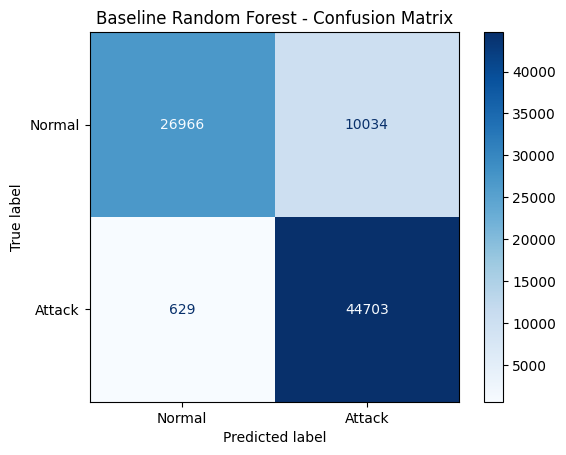

In [10]:
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
).plot(cmap="Blues", values_format="d")

plt.title("Baseline Random Forest - Confusion Matrix")
plt.show()

## Model Evaluation and Results

A baseline Random Forest classifier was trained to distinguish normal network traffic from attack traffic using the UNSW-NB15 dataset.

### Evaluation Metrics

- **Accuracy:** 87.05%
- **ROC-AUC:** 0.9791
- **Attack precision:** 81.67%
- **Attack recall:** 98.61%
- **Attack F1-score:** 89.34%
- **Normal recall:** 72.88%

### Key Findings

1. The model detected 44,703 attack records correctly and missed 629 attacks.
2. Attack recall of 98.61% indicates that the model identified most actual attacks in the test dataset.
3. The model incorrectly flagged 10,034 normal records as attacks, indicating a substantial false-positive problem.
4. Normal recall was 72.88%, showing that identifying normal traffic remains an area for improvement.
5. The ROC-AUC of 0.9791 indicates strong discrimination between the two classes across different classification thresholds.

### Limitations

- The results are specific to the UNSW-NB15 test dataset and may not generalize to real-world network traffic.
- False positives could generate excessive security alerts.
- False negatives represent attacks that the model failed to detect.
- Only a baseline Random Forest model was evaluated; further comparisons and tuning are needed.
- Performance should be evaluated on additional network datasets before considering practical deployment.

### Conclusion

The baseline model achieved 87.05% accuracy and 98.61% attack recall. Although it detected most attacks in the test dataset, the number of false positives highlights the need to improve the balance between attack detection and normal traffic recognition. The model provides a foundation for further experimentation and is not yet suitable for deployment without additional validation.